# Simulación de congestión en una bodega con un Modelo Oculto de Markov (HMM)

**Asignatura:** Simulación - Módulo 2. Actividad didáctica 2

**Estudiante:** Daniela María Sánchez Sánchez  
**Herramienta:** Google Colab / Python  
planteamiento y primera simulación

En esta actividad quiero explorar cómo se podrían representar los cambios de carga de trabajo en una bodega usando probabilidades. Es un **ejercicio académico con datos simulados**; por ahora no estoy usando registros reales de ninguna empresa. Los valores son supuestos iniciales para aprender el modelo y después probar qué pasa cuando se modifican.

## 1. Problema que voy a estudiar

Durante las operaciones de una bodega pueden presentarse momentos con trabajo fluido y otros con congestión. Aunque se puede medir cuánto tarda el registro de las guías, el estado operativo no siempre se identifica directamente con un solo dato.

**Pregunta principal:** ¿cómo se relacionan los cambios de estado operativo con la frecuencia de registros lentos?

**Alcance:** voy a representar cada hora de trabajo como un intervalo. Para cada hora se genera una observación que clasifica el tiempo promedio de registro de guías como **rápido** (hasta 10 minutos), **normal** (más de 10 y hasta 20 minutos) o **lento** (más de 20 minutos). Estos límites también son supuestos del ejercicio.

**Objetivo:** diseñar un HMM sencillo que genere estados y observaciones, y después comparar escenarios con distintas probabilidades de congestión.

### Preguntas de investigación

- **P1:** ¿Cómo representar la congestión de la bodega con estados ocultos y observaciones visibles?
- **P2:** ¿Cómo cambian los resultados al modificar las probabilidades del modelo?
- **P3:** ¿Cómo comprobar que los resultados se pueden repetir y qué tan sensibles son a cambios en las condiciones iniciales?


## 2. ¿Qué es un HMM en este caso?

Un **Modelo Oculto de Markov** se usa cuando existe una situación interna que no observamos directamente, pero sí podemos ver algunas señales relacionadas con ella.

- **S (estados ocultos):** `Fluida` y `Congestionada`.
- **V (observaciones):** `Rápido`, `Normal` y `Lento`.
- **A (transición):** probabilidad de pasar de un estado a otro de una hora a la siguiente.
- **B (emisión):** probabilidad de observar un tiempo de registro según el estado oculto.
- **π (inicial):** probabilidad de comenzar en cada estado.

La idea de Markov es que para calcular el siguiente estado usamos el estado actual; no necesitamos toda la historia anterior. En un HMM la observación depende del estado oculto de ese momento.

**Nota:** en el ejercicio de simulación podemos ver los estados internos porque el programa los genera. En una aplicación real esos estados se tendrían que *inferir* a partir de las observaciones, por ejemplo con Viterbi.


## 3. Matrices iniciales (hipótesis del ejercicio)

Al comenzar supongo que hay 70 % de probabilidad de estar en operación fluida y 30 % de congestión:

\[\pi=(0.70,\ 0.30)\]

Matriz de transición **A** (filas = estado actual, columnas = estado siguiente):

| Estado actual / siguiente | Fluida | Congestionada |
|---|---:|---:|
| Fluida | 0.85 | 0.15 |
| Congestionada | 0.30 | 0.70 |

Matriz de emisión **B** (filas = estado oculto, columnas = resultado visible):

| Estado | Rápido | Normal | Lento |
|---|---:|---:|---:|
| Fluida | 0.70 | 0.25 | 0.05 |
| Congestionada | 0.10 | 0.30 | 0.60 |

Cada fila debe sumar **1**, porque representa todas las posibilidades de un mismo caso. Estos porcentajes **no se obtuvieron de una base de datos**: sirven como punto de partida y deben analizarse después mediante escenarios.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mantengo esta semilla para repetir los mismos resultados.
semilla = 2026
rng = np.random.default_rng(semilla)

estados = ["Fluida", "Congestionada"]
observaciones = ["Rápido", "Normal", "Lento"]

pi = np.array([0.70, 0.30])
A = np.array([
    [0.85, 0.15],
    [0.30, 0.70]
])
B = np.array([
    [0.70, 0.25, 0.05],
    [0.10, 0.30, 0.60]
])

print("Estados:", estados)
print("Observaciones:", observaciones)
print("Probabilidades iniciales:", pi)


Estados: ['Fluida', 'Congestionada']
Observaciones: ['Rápido', 'Normal', 'Lento']
Probabilidades iniciales: [0.7 0.3]


### 3.1. Comprobar que las probabilidades están bien definidas

Antes de simular reviso que ningún valor sea negativo, que ninguno supere 1 y que las filas de las matrices sumen 1. Si alguna probabilidad está mal, el programa se detiene y me avisa.

In [ ]:
assert np.all((pi >= 0) & (pi <= 1)) and np.isclose(pi.sum(), 1)
assert np.all((A >= 0) & (A <= 1)) and np.allclose(A.sum(axis=1), 1)
assert np.all((B >= 0) & (B <= 1)) and np.allclose(B.sum(axis=1), 1)
assert A.shape == (len(estados), len(estados))
assert B.shape == (len(estados), len(observaciones))
print("Revisión correcta: las matrices contienen probabilidades válidas.")


Revisión correcta: las matrices contienen probabilidades válidas.


## 4. Primera simulación

Ahora voy a simular **30 horas de operación**. Primero elijo un estado según π; luego, para cada hora, genero un resultado visible según la matriz B y el estado correspondiente. Para la siguiente hora utilizo la matriz A.

Esto es solo una demostración inicial: **30 horas no son suficientes para sacar conclusiones generales**. Más adelante haré muchas repeticiones y compararé tres escenarios.

In [ ]:
def simular_bodega(horas, pi, A, B, semilla):
    rng_local = np.random.default_rng(semilla)
    estado_actual = rng_local.choice(len(estados), p=pi)
    filas = []

    for hora in range(1, horas + 1):
        observado = rng_local.choice(len(observaciones), p=B[estado_actual])
        filas.append({
            "Hora": hora,
            "Estado oculto (solo validación)": estados[estado_actual],
            "Tiempo observado": observaciones[observado]
        })
        estado_actual = rng_local.choice(len(estados), p=A[estado_actual])

    return pd.DataFrame(filas)

resultado = simular_bodega(30, pi, A, B, semilla)
print("Primeras 10 horas simuladas:")
print(resultado.head(10).to_string(index=False))


Primeras 10 horas simuladas:
 Hora Estado oculto (solo validación) Tiempo observado
    1                          Fluida           Rápido
    2                          Fluida           Rápido
    3                          Fluida           Normal
    4                   Congestionada           Normal
    5                   Congestionada           Normal
    6                   Congestionada            Lento
    7                   Congestionada            Lento
    8                   Congestionada            Lento
    9                   Congestionada           Normal
   10                          Fluida           Rápido


### 4.1. ¿Qué se observó?

En esta tabla muestro el conteo de resultados rápidos, normales y lentos. Para no confundir el análisis, debo recordar que estos datos son generados por el programa a partir de mis probabilidades de ejemplo.

In [ ]:
conteos = resultado["Tiempo observado"].value_counts().reindex(observaciones, fill_value=0)
porcentajes = (conteos / len(resultado) * 100).round(2)
resumen = pd.DataFrame({"Horas": conteos, "Porcentaje (%)": porcentajes})
print(resumen.to_string())
print(f"\nPorcentaje de registros lentos: {porcentajes['Lento']:.2f} %")


                  Horas  Porcentaje (%)
Tiempo observado                       
Rápido               17           56.67
Normal               10           33.33
Lento                 3           10.00

Porcentaje de registros lentos: 10.00 %


### 4.2. Gráfica de las observaciones

Esta primera figura permite ver la frecuencia de cada resultado. En la actividad final agregaré comparaciones entre escenarios y medidas estadísticas.

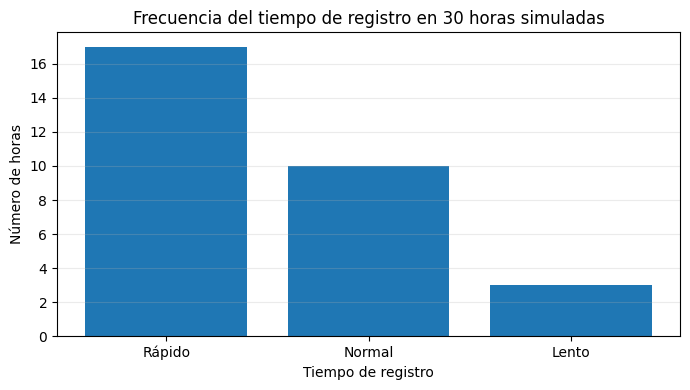

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(conteos.index, conteos.values)
ax.set_title("Frecuencia del tiempo de registro en 30 horas simuladas")
ax.set_xlabel("Tiempo de registro")
ax.set_ylabel("Número de horas")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig("01_Frecuencia_Registros_Markov.png", dpi=300, bbox_inches="tight")
plt.show()


## 5. Avances y actividades pendientes

En esta actividad desarrollé una simulación de la congestión en una bodega de logística utilizando un Modelo Oculto de Markov (HMM) en Python.

Primero definí el problema, los estados ocultos, las observaciones y las matrices de probabilidades. Después ejecuté diferentes simulaciones para analizar cómo cambia el comportamiento de la bodega.

### Actividades realizadas

1. Definí los estados de operación fluida y congestionada.
2. Construí las matrices de transición y emisión, junto con las probabilidades iniciales.
3. Realicé una primera simulación de 30 horas.
4. Comparé tres escenarios: operación habitual, mayor congestión y menor congestión.
5. Ejecuté 50 repeticiones de 1.000 horas por escenario y calculé los resultados estadísticos.
6. Utilicé el algoritmo Viterbi para estimar los estados ocultos, obteniendo una coincidencia del 83,33 % en las 30 horas simuladas.
7. Apliqué el algoritmo Forward para calcular la probabilidad de las observaciones.
8. Analicé cómo cambian los resultados al modificar las probabilidades iniciales.

### Actividades pendientes

1. Revisar las diez referencias académicas y comprobar sus datos bibliográficos e indexación.
2. Organizar el artículo académico en Word, incluyendo los resultados, tablas, gráficas y referencias en formato IEEE.
3. Publicar el proyecto completo en GitHub, con el código y las evidencias.
4. Preparar el video de sustentación de 2 a 3 minutos.

### Fuentes de consulta

- [Documentación de hmmlearn](https://hmmlearn.readthedocs.io/en/latest/tutorial.html)
- [Tufts University: Dynamic Programming for Hidden Markov Models](https://www.cs.tufts.edu/cs/136/2023s/cp5.html)

Estas fuentes me sirven para comprender mejor el funcionamiento de los modelos ocultos de Markov. Todavía debo complementar la investigación con los diez artículos académicos que solicita el profesor.




In [ ]:

# Comparación de tres escenarios de la bodega

escenarios = {
    "Operación habitual": A,

    "Mayor congestión": np.array([
        [0.60, 0.40],
        [0.10, 0.90]
    ]),

    "Menor congestión": np.array([
        [0.95, 0.05],
        [0.60, 0.40]
    ])
}

resultados_escenarios = []

for nombre, matriz in escenarios.items():
    # Compruebo que las probabilidades sean válidas
    assert np.allclose(matriz.sum(axis=1), 1)

    # Simulo 1000 horas para cada escenario
    datos = simular_bodega(1000, pi, matriz, B, semilla)

    porcentaje_lento = (
        datos["Tiempo observado"].eq("Lento").mean() * 100
    )

    resultados_escenarios.append({
        "Escenario": nombre,
        "Horas simuladas": len(datos),
        "Registros lentos (%)": round(porcentaje_lento, 2)
    })

tabla_escenarios = pd.DataFrame(resultados_escenarios)
display(tabla_escenarios)



,Escenario,Horas simuladas,Registros lentos (%)
0,Operación habitual,1000,23.3
1,Mayor congestión,1000,48.1
2,Menor congestión,1000,9.1


In [ ]:

# Repito cada escenario para comparar los resultados

repeticiones = 50
resultados = []

for nombre, matriz in escenarios.items():
    for i in range(repeticiones):
        datos = simular_bodega(
            1000, pi, matriz, B, semilla + i
        )

        porcentaje = (
            datos["Tiempo observado"].eq("Lento").mean() * 100
        )

        resultados.append({
            "Escenario": nombre,
            "Porcentaje lento": porcentaje
        })

tabla = pd.DataFrame(resultados)

resumen = tabla.groupby("Escenario")["Porcentaje lento"].agg(
    ["mean", "std", "min", "max", "count"]
)

resumen["Margen IC 95%"] = (
    1.96 * resumen["std"] / np.sqrt(resumen["count"])
)

resumen["IC inferior"] = resumen["mean"] - resumen["Margen IC 95%"]
resumen["IC superior"] = resumen["mean"] + resumen["Margen IC 95%"]

display(resumen.round(2))


,mean,std,min,max,count,Margen IC 95%,IC inferior,IC superior
Escenario,,,,,,,,
Mayor congestión,49.09,2.18,44.5,53.3,50,0.60,48.49,49.70
Menor congestión,9.25,1.15,6.9,12.6,50,0.32,8.93,9.57
Operación habitual,23.46,1.94,19.3,29.5,50,0.54,22.93,24.00


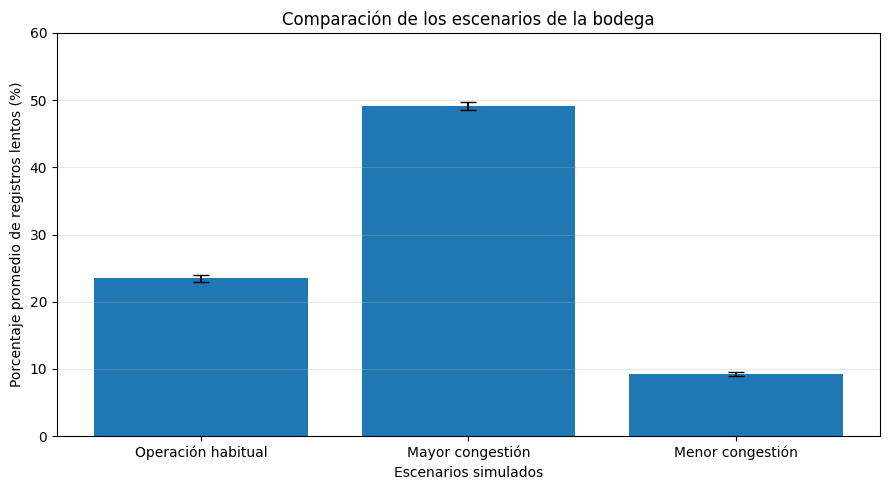

In [ ]:

# Gráfica de comparación de los tres escenarios

import matplotlib.pyplot as plt

orden = [
    "Operación habitual",
    "Mayor congestión",
    "Menor congestión"
]

datos_grafica = resumen.loc[orden]

plt.figure(figsize=(9, 5))

plt.bar(
    orden,
    datos_grafica["mean"],
    yerr=datos_grafica["Margen IC 95%"],
    capsize=6
)

plt.title("Comparación de los escenarios de la bodega")
plt.xlabel("Escenarios simulados")
plt.ylabel("Porcentaje promedio de registros lentos (%)")
plt.ylim(0, 60)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Guardar la gráfica con buena resolución
plt.savefig("02_Comparacion_Escenarios_Markov.png", dpi=300)

plt.show()


In [ ]:

# Algoritmo de Viterbi para estimar los estados de la bodega

# Tomo los tiempos observados de la primera simulación
secuencia = resultado["Tiempo observado"].tolist()
indices = [observaciones.index(x) for x in secuencia]

cantidad = len(indices)
n_estados = len(estados)

# Creo las tablas para calcular los estados más probables
probabilidades = np.zeros((cantidad, n_estados))
anteriores = np.zeros((cantidad, n_estados), dtype=int)

probabilidades[0] = pi * B[:, indices[0]]

# Calculo las probabilidades para las siguientes horas
for t in range(1, cantidad):
    for j in range(n_estados):
        opciones = probabilidades[t-1] * A[:, j]
        mejor = np.argmax(opciones)

        anteriores[t, j] = mejor
        probabilidades[t, j] = opciones[mejor] * B[j, indices[t]]

# Recupero la secuencia de estados más probable
camino = np.zeros(cantidad, dtype=int)
camino[-1] = np.argmax(probabilidades[-1])

for t in range(cantidad - 2, -1, -1):
    camino[t] = anteriores[t + 1, camino[t + 1]]

# Muestro los resultados
tabla_viterbi = pd.DataFrame({
    "Hora": range(1, cantidad + 1),
    "Tiempo observado": secuencia,
    "Estado estimado": [estados[i] for i in camino]
})

print("Estados estimados con Viterbi:")
display(tabla_viterbi.head(10))


Estados estimados con Viterbi:


,Hora,Tiempo observado,Estado estimado
0,1,Rápido,Fluida
1,2,Rápido,Fluida
2,3,Normal,Fluida
3,4,Normal,Fluida
4,5,Normal,Fluida
5,6,Lento,Congestionada
6,7,Lento,Congestionada
7,8,Lento,Congestionada
8,9,Normal,Fluida
9,10,Rápido,Fluida


In [ ]:

# Comparo los estados reales de la simulación
# con los estados que estimó Viterbi

comparacion = tabla_viterbi.copy()

comparacion["Estado simulado"] = resultado[
    "Estado oculto (solo validación)"
].to_numpy()

comparacion["Coincide"] = (
    comparacion["Estado estimado"] ==
    comparacion["Estado simulado"]
)

porcentaje_aciertos = comparacion["Coincide"].mean() * 100

print("Comparación de las primeras 10 horas:")
display(comparacion.head(10))

print(
    f"Coincidencia en las 30 horas: "
    f"{porcentaje_aciertos:.2f}%"
)


Comparación de las primeras 10 horas:


,Hora,Tiempo observado,Estado estimado,Estado simulado,Coincide
0,1,Rápido,Fluida,Fluida,True
1,2,Rápido,Fluida,Fluida,True
2,3,Normal,Fluida,Fluida,True
3,4,Normal,Fluida,Congestionada,False
4,5,Normal,Fluida,Congestionada,False
5,6,Lento,Congestionada,Congestionada,True
6,7,Lento,Congestionada,Congestionada,True
7,8,Lento,Congestionada,Congestionada,True
8,9,Normal,Fluida,Congestionada,False
9,10,Rápido,Fluida,Fluida,True


Coincidencia en las 30 horas: 83.33%


In [ ]:

# Algoritmo Forward para el modelo de la bodega

secuencia = resultado["Tiempo observado"].tolist()
indices = [observaciones.index(x) for x in secuencia]

# Probabilidades de la primera hora
alpha = pi * B[:, indices[0]]
escala = alpha.sum()
alpha = alpha / escala

log_probabilidad = np.log(escala)

# Recorro las demás horas
for t in range(1, len(indices)):
    alpha = (alpha @ A) * B[:, indices[t]]

    escala = alpha.sum()
    alpha = alpha / escala

    log_probabilidad += np.log(escala)

print("RESULTADOS DEL ALGORITMO FORWARD")
print("Horas analizadas:", len(indices))
print("Log-probabilidad de la secuencia:",
      round(log_probabilidad, 4))

print("Probabilidad de la secuencia:",
      f"{np.exp(log_probabilidad):.10e}")


RESULTADOS DEL ALGORITMO FORWARD
Horas analizadas: 30
Log-probabilidad de la secuencia: -26.3689
Probabilidad de la secuencia: 3.5328683700e-12


In [ ]:

# Comparación de Forward en los tres escenarios

def calcular_forward(matriz, secuencia):
    indices = [observaciones.index(x) for x in secuencia]

    alpha = pi * B[:, indices[0]]
    escala = alpha.sum()
    alpha = alpha / escala
    log_prob = np.log(escala)

    for t in range(1, len(indices)):
        alpha = (alpha @ matriz) * B[:, indices[t]]
        escala = alpha.sum()
        alpha = alpha / escala
        log_prob += np.log(escala)

    return log_prob

secuencia = resultado["Tiempo observado"].tolist()
comparacion_forward = []

for nombre, matriz in escenarios.items():
    valor = calcular_forward(matriz, secuencia)

    comparacion_forward.append({
        "Escenario": nombre,
        "Log-probabilidad": round(valor, 4)
    })

tabla_forward = pd.DataFrame(comparacion_forward)
display(tabla_forward)


,Escenario,Log-probabilidad
0,Operación habitual,-26.3689
1,Mayor congestión,-31.6488
2,Menor congestión,-26.5501


In [ ]:

# Prueba de sensibilidad a las probabilidades iniciales

def forward_con_inicio(pi_inicio):
    indices = [observaciones.index(x) for x in secuencia]

    alpha = pi_inicio * B[:, indices[0]]
    escala = alpha.sum()
    alpha = alpha / escala
    log_prob = np.log(escala)

    for t in range(1, len(indices)):
        alpha = (alpha @ A) * B[:, indices[t]]
        escala = alpha.sum()
        alpha = alpha / escala
        log_prob += np.log(escala)

    return log_prob

condiciones_iniciales = {
    "70% fluida - 30% congestionada": np.array([0.70, 0.30]),
    "50% fluida - 50% congestionada": np.array([0.50, 0.50]),
    "30% fluida - 70% congestionada": np.array([0.30, 0.70])
}

resultados_sensibilidad = []

for nombre, inicio in condiciones_iniciales.items():
    valor = forward_con_inicio(inicio)

    resultados_sensibilidad.append({
        "Condición inicial": nombre,
        "Log-probabilidad": round(valor, 4)
    })

tabla_sensibilidad = pd.DataFrame(resultados_sensibilidad)
display(tabla_sensibilidad)


,Condición inicial,Log-probabilidad
0,70% fluida - 30% congestionada,-26.3689
1,50% fluida - 50% congestionada,-26.6655
2,30% fluida - 70% congestionada,-27.0889


## 6. Estado del arte

Para desarrollar esta actividad empecé a investigar cómo se han utilizado los Modelos Ocultos de Markov en diferentes procesos.

Encontré un estudio de Liu y otros autores (2022), donde se utiliza este modelo para reconocer los estados de los vehículos en instalaciones logísticas. Este trabajo me permitió observar que los HMM pueden ser útiles cuando la información disponible presenta errores o interferencias.

También revisé una investigación de Borucka y otros autores (2023), donde se utilizan modelos ocultos de Markov para analizar las entregas de materiales a una empresa. Me pareció interesante porque demuestra que las probabilidades permiten estudiar procesos logísticos que cambian con el tiempo.

Por último, encontré el trabajo de Varnukhov (2024), que aplica los HMM al análisis de procesos empresariales. Este estudio me ayudó a relacionar el modelo con situaciones operativas donde se dispone de información sobre los resultados, pero no siempre se conoce el estado interno del proceso.

En mi proyecto estoy utilizando esta misma idea para representar dos estados de una bodega: operación fluida y congestionada. A partir de los tiempos de registro, busco analizar cómo cambia el comportamiento del sistema.

Por ahora, el modelo trabaja con datos simulados y probabilidades definidas como supuestos. Una limitación importante es que todavía no se ha probado con información real de una empresa.

### Referencias consultadas

1 Y. Liu, M. Guo, S. Hu y W. Zhe, "Enhancing Vehicle State Recognition in Logistics Industrial Parks via Dynamic Hidden Markov Model", IEEE ETFA, 2022. https://doi.org/10.1109/ETFA52439.2022.9921466

2 A. Borucka et al., "Supply Sequence Modelling Using Hidden Markov Models", Applied Sciences, vol. 13, n.º 1, art. 231, 2023. https://doi.org/10.3390/app13010231

3 A. Y. Varnukhov, "Hidden Markov model: Method for building a business process model", Business Informatics, 2024. https://doi.org/10.17323/2587-814X.2024.3.41.55

### Comparación de los estudios consultados

| Autor y año | Tema estudiado | Relación con mi proyecto |
|---|---|---|
| Liu y colaboradores (2022) | Identificación de estados de vehículos en centros logísticos. | Me ayuda a comprender cómo estimar estados que no se observan directamente. |
| Borucka y colaboradores (2023) | Análisis de entregas de materiales mediante HMM. | Se relaciona con el estudio de procesos logísticos utilizando probabilidades. |
| Varnukhov (2024) | Modelación de procesos empresariales mediante HMM. | Me sirve como referencia para representar cambios en el funcionamiento de una bodega. |

### Diferencia de mi proyecto

Mi ejercicio se centra en simular una bodega con dos estados operativos y analizar los tiempos de registro de mercancías. A diferencia de los estudios anteriores, por ahora trabajo con probabilidades propuestas y datos simulados. Por eso, mi aporte es principalmente académico y no una solución validada en una empresa real.

### Otras investigaciones relacionadas con mi proyecto

Para complementar el estado del arte, revisé siete publicaciones adicionales que utilizan Modelos Ocultos de Markov en diferentes situaciones.

**4. Zhang y colaboradores (2022).** Estudiaron el diseño de redes de transporte utilizando un HMM y un algoritmo de optimización. Este trabajo se relaciona con mi proyecto porque también considera situaciones de congestión y cambios en las condiciones del sistema.

**5. Raskar y Nema (2022).** Propusieron un Modelo Oculto de Markov modificado para predecir el flujo vehicular. Me sirve para comprender cómo las probabilidades pueden ayudar a estudiar situaciones que cambian con el tiempo.

**6. Zhu y colaboradores (2024).** Utilizaron un HMM para supervisar el desgaste de herramientas industriales. Aunque su aplicación es diferente, muestra cómo se pueden identificar estados internos a partir de información observada.

**7. Martins y colaboradores (2024).** Desarrollaron un método para analizar el estado de funcionamiento de equipos industriales mediante datos de sensores y HMM. Este estudio me ayuda a comprender cómo se pueden reconocer condiciones normales y situaciones de falla.

**8. Sorostinean y colaboradores (2024).** Investigaron cómo detectar comportamientos anormales en maquinaria industrial utilizando HMM y otras técnicas de aprendizaje automático. Su trabajo muestra la importancia de analizar las observaciones para reconocer posibles problemas operativos.

**9. Skau y colaboradores (2024).** Estudiaron cómo construir Modelos Ocultos de Markov a partir de modelos de procesos. Esta investigación se relaciona con la forma en que representé el funcionamiento de una bodega mediante estados y probabilidades.

**10. Miguelez y colaboradores (2025).** Propusieron un modelo basado en HMM para predecir tiempos de procesos industriales e identificar pérdidas de tiempo. Este es uno de los trabajos más cercanos a mi ejercicio, porque también analiza tiempos operativos.

### Relación de estas investigaciones con mi propuesta

Después de revisar estos trabajos, observé que los Modelos Ocultos de Markov se pueden aplicar en transporte, logística, mantenimiento y procesos industriales.

Mi proyecto se enfoca en una situación más sencilla: simular una bodega con dos estados ocultos, operación fluida y congestionada, y tres observaciones posibles, registro rápido, normal y lento.

La principal diferencia es que mi ejercicio utiliza datos simulados y probabilidades propuestas. Por eso, no busco afirmar que el modelo ya funciona en una empresa real, sino comprender su comportamiento y analizar cómo cambian los resultados cuando modifico las probabilidades.

### Referencias adicionales

4 Y. Zhang, W. Xue, W. Wei y H. Nazif, "A public transport network design using a hidden Markov model and an optimization algorithm", *Research in Transportation Economics*, vol. 92, art. 101095, 2022. https://doi.org/10.1016/j.retrec.2021.101095

5 C. Raskar y S. Nema, "Metaheuristic enabled modified hidden Markov model for traffic flow prediction", *Computer Networks*, vol. 206, art. 108780, 2022. https://doi.org/10.1016/j.comnet.2022.108780

6 K. Zhu, X. Li, S. Li y X. Lin, "Physics-informed hidden markov model for tool wear monitoring", *Journal of Manufacturing Systems*, vol. 72, pp. 308–322, 2024. https://doi.org/10.1016/j.jmsy.2023.11.003

7 A. Martins, I. Fonseca, J. T. Farinha, J. Reis y A. J. M. Cardoso, "Prediction maintenance based on vibration analysis and deep learning — A case study of a drying press supported on a Hidden Markov Model", *Applied Soft Computing*, vol. 163, art. 111885, 2024. https://doi.org/10.1016/j.asoc.2024.111885

8 R. Sorostinean, Z. Burghelea y A. Gellert, "Anomaly Detection in Smart Industrial Machinery Through Hidden Markov Models and Autoencoders", *IEEE Access*, vol. 12, 2024. https://doi.org/10.1109/ACCESS.2024.3400970

9 E. Skau, A. Hollis, S. Eidenbenz, K. Rasmussen y B. Alexandrov, "Generating Hidden Markov Models from Process Models Through Nonnegative Tensor Factorization", *ACM Transactions on Modeling and Computer Simulation*, vol. 34, n.º 4, pp. 1–19, 2024. https://doi.org/10.1145/3664813

10 F. Miguelez, J. Doncel y M. D. Ugarte, "An Adaptive Learning Approach to Multivariate Time Forecasting in Industrial Processes", *Applied Stochastic Models in Business and Industry*, vol. 41, n.º 3, art. e70016, 2025. https://doi.org/10.1002/asmb.70016

### Tabla comparativa de las investigaciones restantes

| Investigación | Aplicación del HMM | Relación con mi proyecto |
|---|---|---|
| Zhang et al. (2022) 4 | Diseño y optimización de redes de transporte. | Permite relacionar los modelos probabilísticos con problemas de congestión. |
| Raskar y Nema (2022) 5 | Predicción del flujo vehicular. | Muestra cómo estudiar cambios en un sistema de transporte. |
| Zhu et al. (2024) 6 | Seguimiento del desgaste de herramientas industriales. | Ayuda a comprender la identificación de estados internos. |
| Martins et al. (2024) 7 | Análisis del estado de equipos industriales. | Permite relacionar las observaciones con diferentes condiciones operativas. |
| Sorostinean et al. (2024) 8 | Detección de anomalías en maquinaria. | Muestra cómo identificar posibles problemas a partir de datos observados. |
| Skau et al. (2024) 9 | Construcción de HMM a partir de modelos de procesos. | Se relaciona con la representación de las actividades de una bodega. |
| Miguelez et al. (2025) 10 | Predicción de tiempos en procesos industriales. | Es una referencia cercana al análisis de los tiempos de registro de mercancías. |

### Análisis de las investigaciones

Al comparar estos trabajos, encontré que los Modelos Ocultos de Markov se pueden utilizar para estudiar diferentes procesos que cambian con el tiempo.

En algunos estudios se analizan vehículos y congestión, mientras que otros se enfocan en maquinaria y procesos industriales. Aunque son aplicaciones diferentes, comparten la idea de utilizar observaciones para estudiar estados que no siempre se conocen directamente.

### Diferencia y aporte de mi proyecto

Mi proyecto se enfoca en una bodega de logística y utiliza dos estados: operación fluida y congestionada. A partir de ellos se generan tres tipos de observaciones: registros rápidos, normales y lentos.

Para analizar el modelo realicé simulaciones, comparé tres escenarios y utilicé los algoritmos Forward y Viterbi.

El aporte principal de este ejercicio es mostrar, de manera práctica, cómo las probabilidades pueden representar diferentes condiciones operativas y cómo cambian los resultados cuando se modifican las matrices.

### Limitaciones

Este trabajo utiliza datos simulados y probabilidades propuestas. Por eso, los resultados no se pueden interpretar como mediciones reales de una empresa.

También sería necesario utilizar registros históricos para comprobar si el modelo representa adecuadamente una operación logística real.

## 7. Marco teórico: algoritmo Baum-Welch

El algoritmo Baum-Welch se utiliza para estimar las probabilidades de un Modelo Oculto de Markov a partir de una secuencia de observaciones.

A diferencia de Forward, que calcula la probabilidad de una secuencia, y de Viterbi, que busca los estados ocultos más probables, Baum-Welch permite ajustar los parámetros del modelo.

Este algoritmo utiliza un procedimiento iterativo conocido como Expectation-Maximization (EM), que busca mejorar la probabilidad que el modelo asigna a los datos observados.

### ¿Cómo funciona?

1. Se comienza con unas probabilidades iniciales.
2. Se calculan las probabilidades de los estados ocultos utilizando los datos observados.
3. Se actualizan las matrices de transición y emisión, junto con las probabilidades iniciales.
4. Se repite el procedimiento hasta cumplir un criterio de convergencia o alcanzar el número máximo de iteraciones.

### Relación con mi proyecto

En mi simulación de la bodega definí las matrices de probabilidad utilizando valores supuestos para representar la operación fluida y congestionada.

Si en un futuro tuviera información histórica de los tiempos de registro de mercancías, podría utilizar Baum-Welch para estimar las probabilidades del modelo a partir de esas observaciones.

Por ahora, en este ejercicio implementé Forward y Viterbi, mientras que Baum-Welch se presenta como parte del marco teórico y como una posibilidad para mejorar el modelo.

También es importante reconocer que Baum-Welch no garantiza encontrar la mejor solución global y que sus resultados pueden depender de las probabilidades utilizadas al comenzar.

## 8. Análisis de resultados y preguntas de investigación

En esta parte analicé los resultados obtenidos con el Modelo Oculto de Markov aplicado a la congestión de una bodega. Para ello utilicé las matrices de probabilidad, realicé simulaciones y comparé diferentes escenarios.

### P1. ¿Cómo puede representarse la congestión de una bodega mediante un Modelo Oculto de Markov?

Representé el funcionamiento de la bodega utilizando dos estados ocultos: operación fluida y congestionada.

También definí tres observaciones relacionadas con los tiempos de registro de las mercancías: rápido, normal y lento.

Mediante las matrices de transición y emisión pude simular cómo cambia el estado de la bodega y cómo estos cambios influyen en los tiempos observados.

### P2. ¿Cómo influyen las probabilidades del modelo en los resultados?

Para responder esta pregunta comparé tres escenarios y realicé 50 repeticiones de 1.000 horas simuladas por escenario.

Los porcentajes promedio de registros lentos fueron:

- Operación habitual: 23,46 %.
- Mayor congestión: 49,09 %.
- Menor congestión: 9,25 %.

Al comparar los resultados observé que, cuando aumenté las probabilidades de congestión en la matriz de transición, también aumentó la frecuencia de registros lentos.

Por el contrario, cuando utilicé una matriz que favorecía la operación fluida, el porcentaje de registros lentos disminuyó.

Esto me permitió comprender cómo los parámetros de un modelo probabilístico pueden influir en los resultados de una simulación.

### P3. ¿Qué tan reproducible y sensible es el modelo?

Para comprobar la reproducibilidad utilicé semillas aleatorias fijas, de manera que las simulaciones se puedan repetir bajo las mismas condiciones.

También cambié las probabilidades iniciales de la bodega y comparé los resultados de Forward.

Obtuve las siguientes log-probabilidades:

- 70 % fluida y 30 % congestionada: -26,3689.
- 50 % fluida y 50 % congestionada: -26,6655.
- 30 % fluida y 70 % congestionada: -27,0889.

Estos resultados muestran que la probabilidad asignada a la secuencia observada cambia cuando se modifican las condiciones iniciales.

### Resultado del algoritmo Viterbi

Al comparar los estados estimados por Viterbi con los estados originales de la simulación, obtuve una coincidencia del 83,33 % en las 30 horas analizadas.

Esto corresponde a 25 estados identificados correctamente de un total de 30.

El resultado demuestra que Viterbi pudo recuperar gran parte de los estados simulados, aunque también presentó errores de clasificación.

### Limitaciones del análisis

Es importante aclarar que trabajé con datos simulados y probabilidades establecidas como supuestos académicos.

Por lo tanto, los resultados permiten estudiar el funcionamiento del HMM, pero todavía no demuestran cómo se comportaría una bodega real.

También sería necesario evaluar más secuencias para obtener conclusiones generales sobre la precisión de Viterbi y la sensibilidad del modelo.

## 9. Conclusiones y trabajo futuro

### Conclusiones

Con el desarrollo de esta actividad pude comprender mejor cómo funcionan los Modelos Ocultos de Markov y cómo se pueden utilizar para representar situaciones que cambian con el tiempo.

Al aplicar el modelo a una bodega de logística, logré simular dos estados operativos: fluida y congestionada. También pude observar cómo estos estados se relacionan con los tiempos de registro de mercancías.

Una de las partes que más me ayudó a comprender el modelo fue comparar los tres escenarios. En la operación habitual obtuve un promedio de 23,46 % de registros lentos, mientras que en el escenario de mayor congestión aumentó al 49,09 % y en el de menor congestión disminuyó al 9,25 %.

También utilicé el algoritmo Viterbi para identificar los estados ocultos. En una simulación de 30 horas, el algoritmo coincidió con el estado original en el 83,33 % de los casos. Este resultado fue útil para entender cómo se pueden estimar estados a partir de observaciones, aunque no significa que siempre se obtenga ese porcentaje de aciertos.

Con Forward pude analizar la probabilidad de una secuencia de observaciones y comprobar que sus resultados cambian cuando modificamos las probabilidades del modelo.

Finalmente, comprendí la importancia de utilizar semillas aleatorias para reproducir las simulaciones y comparar diferentes escenarios bajo condiciones controladas.

### Trabajo futuro

Como mejora del proyecto, me gustaría utilizar información histórica de una bodega real para comprobar si las probabilidades propuestas representan adecuadamente su funcionamiento.

También sería interesante implementar Baum-Welch para estimar las matrices a partir de los datos, evaluar Viterbi con más secuencias y estudiar otros factores que pueden causar congestión, como la cantidad de mercancía recibida y la disponibilidad de personal.

Por ahora, considero que esta simulación me permitió aplicar los conceptos vistos en Ingeniería de Simulación y fortalecer mis conocimientos de programación en Python.

In [ ]:

# Versiones de las herramientas utilizadas

import platform
import numpy as np
import pandas as pd
import matplotlib

print("Información de mi simulación")
print("------------------------------")
print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Semilla utilizada:", semilla)


Información de mi simulación
------------------------------
Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
Matplotlib: 3.10.0
Semilla utilizada: 2026


In [ ]:

# Guardo los resultados de mi simulación

tabla.to_csv(
    "03_Repeticiones_Markov.csv",
    index=False
)

resumen.reset_index().to_csv(
    "04_Resumen_Estadistico_Markov.csv",
    index=False
)

print("Los archivos CSV se generaron correctamente.")


Los archivos CSV se generaron correctamente.
